Importar el dataset directo de Keggle,

#Predicción de Churn en Clientes de Telecomunicaciones
Introducción

El objetivo de este proyecto es analizar y predecir el abandono de clientes (churn) en una empresa de telecomunicaciones utilizando técnicas de análisis de datos y machine learning.

La retención de clientes representa un aspecto estratégico del negocio, ya que reducir el churn permite disminuir costos de adquisición y mejorar la rentabilidad.

A lo largo del trabajo se desarrolló un pipeline completo de ciencia de datos que incluye:

Análisis exploratorio de datos (EDA)
Limpieza y preprocesamiento
Construcción de modelos predictivos
Optimización mediante GridSearchCV
Evaluación y comparación de desempeño

In [1]:
import kagglehub

# Descargar dataset
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [2]:
import os

os.listdir(path)

['WA_Fn-UseC_-Telco-Customer-Churn.csv']

In [3]:
# IMPORTS

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import GridSearchCV

##Análisis inicial

Dataset utilizado: Se utilizó el dataset “Telco Customer Churn” obtenido desde Kaggle, el cual contiene información demográfica, contractual y de facturación de clientes de una empresa de telecomunicaciones.

El dataset cuenta con:

7043 registros
21 variables
Variables numéricas y categóricas

In [4]:

file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
nulls = df.isnull().sum().to_frame().T
nulls.index = ["Valores nulos"]

nulls

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
Valores nulos,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:

sns.set(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8,5)

In [9]:
palette = {"No": "#4CAF50", "Yes": "#F44336"}

<Axes: xlabel='Contract', ylabel='count'>

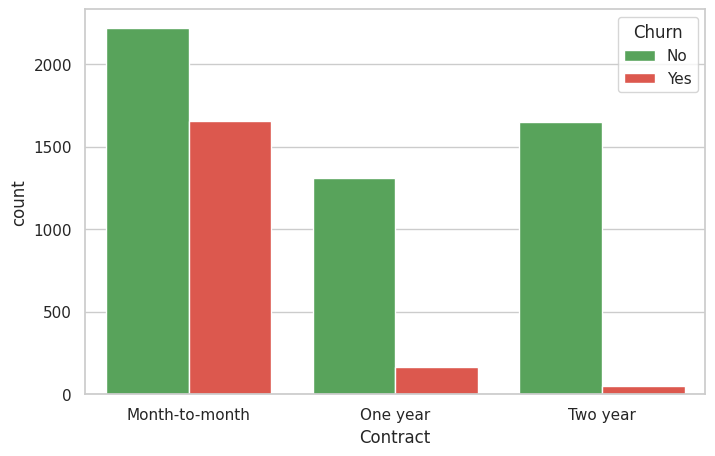

In [10]:
sns.countplot(x="Contract", hue="Churn", data=df, palette=palette)

###Limpieza y Preprocesamiento de Datos

Durante la exploración se detectó que la variable TotalCharges se encontraba almacenada como texto (object) debido a valores vacíos.

Para corregir este problema se realizó la conversión a formato numérico:

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isnull().sum()

np.int64(11)

In [12]:
df = df.dropna()
df.shape

(7032, 21)

#Exploratory Data Analysis (EDA)

###Distribución de la variable objetivo

La variable objetivo presenta un desbalance moderado, donde aproximadamente el 26.6% de los clientes han abandonado el servicio (churn), mientras que el 73.4% permanecen activos.
Este nivel de desbalance no es extremo, pero debe ser considerado al momento de evaluar el modelo, especialmente en métricas como recall y ROC AUC.

In [13]:
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True)

,proportion
Churn,
No,0.734215
Yes,0.265785


##Churn según tipo de contrato

Los clientes con contratos mensuales presentan una tasa de abandono significativamente mayor en comparación con contratos anuales o bianuales.

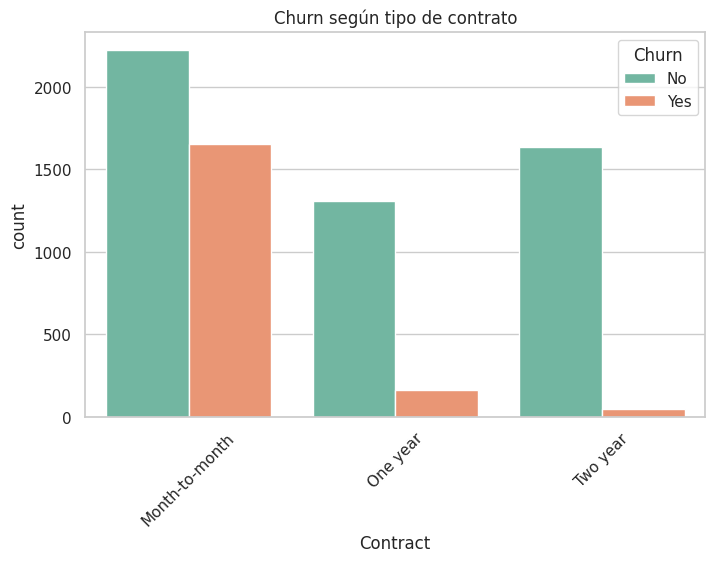

In [14]:

sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn según tipo de contrato")
plt.xticks(rotation=45)
plt.show()

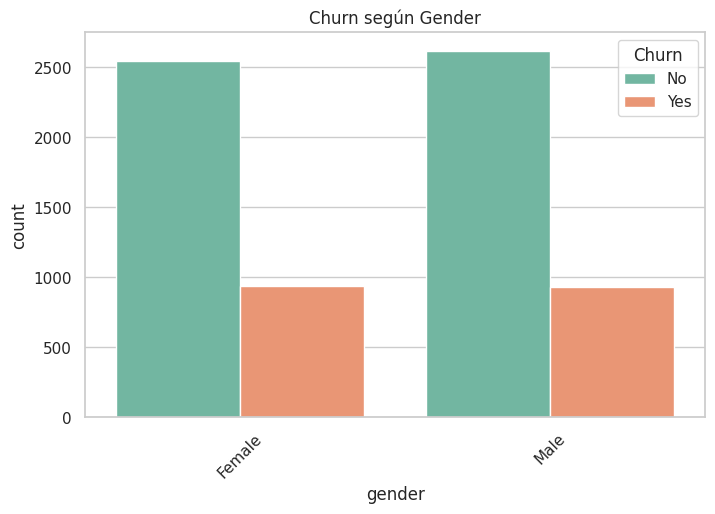

In [15]:
sns.countplot(x="gender", hue="Churn", data=df)
plt.title("Churn según Gender")
plt.xticks(rotation=45)
plt.show()

##Churn según antigüedad

Los clientes con menor antigüedad presentan mayor probabilidad de abandono.

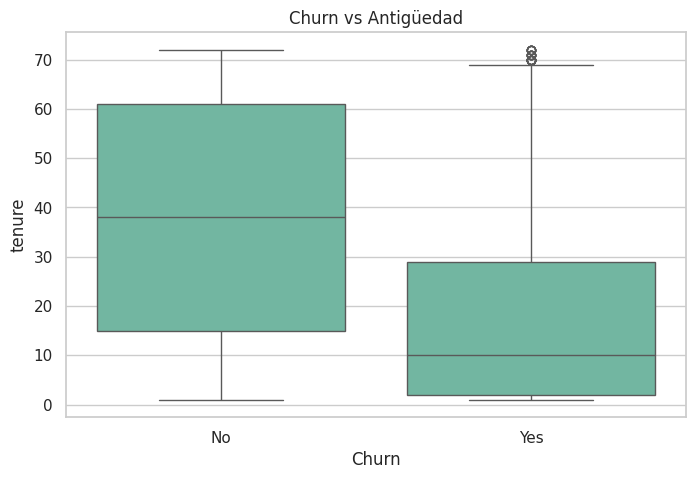

In [16]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Churn vs Antigüedad")
plt.show()

##Churn según cargos mensuales

Los clientes con cargos mensuales más elevados tienden a presentar mayor tasa de churn.

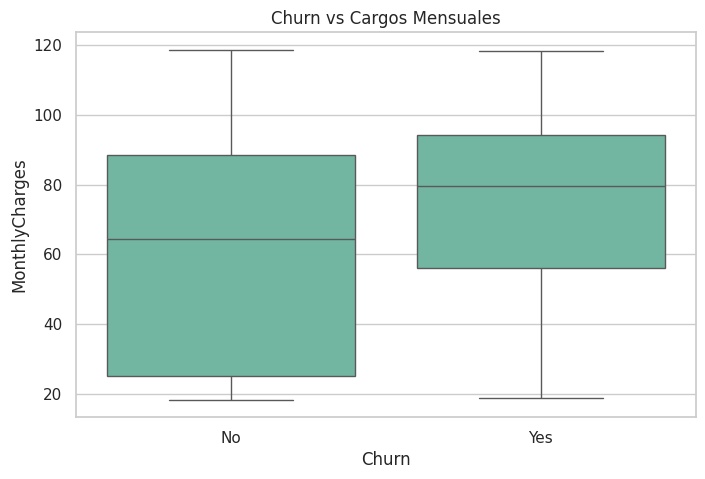

In [17]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Churn vs Cargos Mensuales")
plt.show()

#Resumen del EDA

El análisis exploratorio permitió identificar patrones claros asociados al abandono de clientes:

*Contratos mensuales presentan mayor churn.

*Clientes nuevos tienen mayor riesgo de abandono.

*Clientes con cargos mensuales elevados presentan mayor probabilidad de churn.

Estos hallazgos sugieren oportunidades de negocio orientadas a:

Incentivar contratos de mayor duración.

*Mejorar la experiencia inicial del cliente.

*Revisar estrategias de precios.

#Preprocesamiento para Machine Learning

Se construyó un pipeline de preprocesamiento utilizando scikit-learn.

Variables numéricas:

- Imputación mediante mediana

- Escalado con StandardScaler

Variables categóricas:

- Imputación por valor más frecuente

- Codificación OneHotEncoder

In [18]:
X = df.drop(["Churn", "customerID"], axis=1)
y = df["Churn"]

In [19]:
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns

print("Categóricas:", list(cat_cols))
print("Numéricas:", list(num_cols))

Categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [20]:
num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [21]:
cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, num_cols),
        ("cat", cat_transformer, cat_cols)
    ]
)

In [23]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(5625, 19) (1407, 19)


#Modelo Baseline: Logistic Regression

In [24]:
pipe_log = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [25]:
pipe_log.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model', LogisticRegression(max_iter=1000))])

#Optimización con GridSearchCV

Con el objetivo de mejorar el desempeño del modelo baseline, se implementó una búsqueda de hiperparámetros utilizando GridSearchCV.

La optimización se realizó utilizando validación cruzada de 5 folds y ROC AUC como métrica principal.

Mejores hiperparámetros

- model__C = 10

- model__solver = lbfgs

Resultado obtenido

- Best ROC AUC CV: 0.846

In [26]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["liblinear", "lbfgs"]
}

In [27]:
grid_search = GridSearchCV(
    pipe_log,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

In [28]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('o...
                                                                         Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                                       ('model',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.1, 1, 10],
                         'model__solver': ['liblinear', 'lbfgs']},
             scoring='roc_auc')

In [29]:
print("Best Parameters:", grid_search.best_params_)
print("Best ROC AUC:", grid_search.best_score_)

Best Parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best ROC AUC: 0.8462044587689392


In [30]:
best_model = grid_search.best_estimator_

y_pred_grid = best_model.predict(X_test)
y_proba_grid = best_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_grid))
print("ROC AUC:", roc_auc_score(y_test, y_proba_grid))
print("\nClassification Report:\n", classification_report(y_test, y_pred_grid))

Accuracy: 0.8002842928216063
ROC AUC: 0.8350878237416589

Classification Report:
               precision    recall  f1-score   support

          No       0.85      0.88      0.87      1033
         Yes       0.64      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.73      0.73      1407
weighted avg       0.79      0.80      0.80      1407



In [31]:
y_pred_log = pipe_log.predict(X_test)
y_proba_log = pipe_log.predict_proba(X_test)[:, 1]

In [32]:

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("ROC AUC:", roc_auc_score(y_test, y_proba_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_log))

Accuracy: 0.8038379530916845
ROC AUC: 0.8359290473207676

Classification Report:
               precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Confusion Matrix:
 [[917 116]
 [160 214]]


#Modelo Random Forest

In [33]:
pipe_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

In [34]:
pipe_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model', RandomForestClassifier(random_state=42))])

In [35]:
y_pred_rf = pipe_rf.predict(X_test)
y_proba_rf = pipe_rf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("ROC AUC:", roc_auc_score(y_test, y_proba_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7874911158493249
ROC AUC: 0.8136612120867004

Classification Report:
               precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407


Confusion Matrix:
 [[927 106]
 [193 181]]


In [36]:
results = pd.DataFrame({
    "Modelo": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.80, 0.79],
    "ROC AUC": [0.83, 0.81],
    "Recall (Churn)": [0.57, 0.48]
})

results

,Modelo,Accuracy,ROC AUC,Recall (Churn)
0,Logistic Regression,0.80,0.83,0.57
1,Random Forest,0.79,0.81,0.48


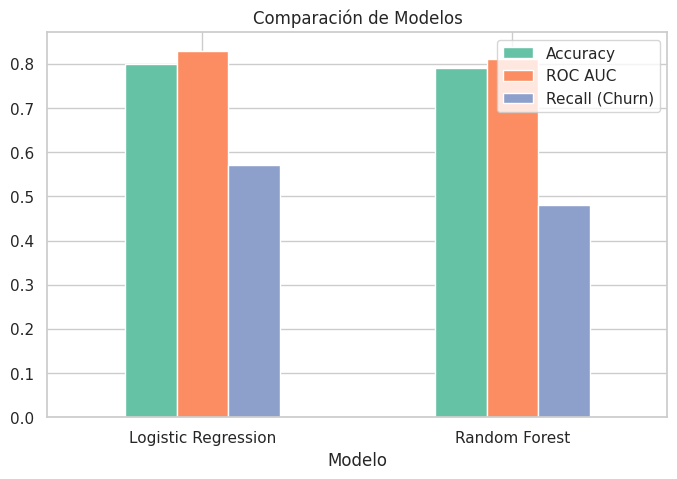

In [37]:
results.set_index("Modelo")[["Accuracy", "ROC AUC", "Recall (Churn)"]].plot(kind="bar")
plt.title("Comparación de Modelos")
plt.xticks(rotation=0)
plt.show()

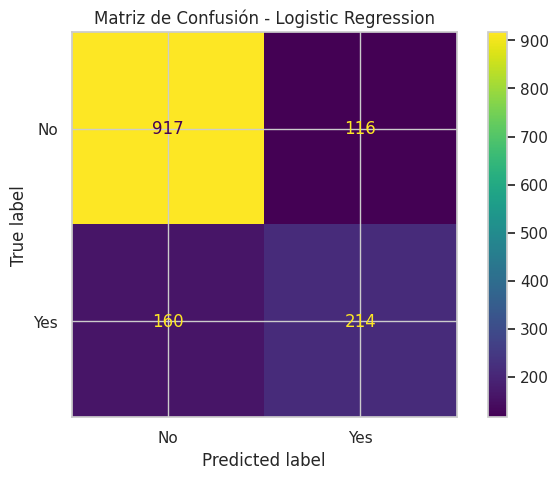

In [38]:

ConfusionMatrixDisplay.from_estimator(pipe_log, X_test, y_test)
plt.title("Matriz de Confusión - Logistic Regression")
plt.show()

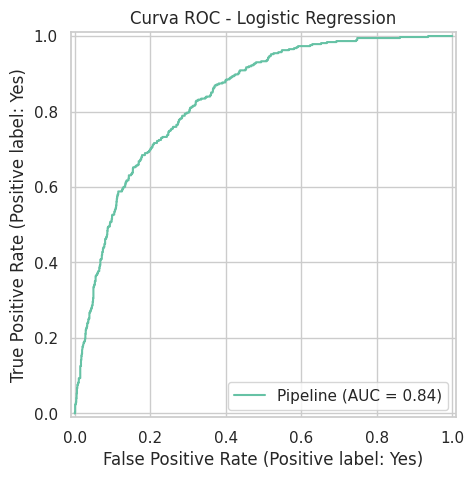

In [39]:

RocCurveDisplay.from_estimator(pipe_log, X_test, y_test)
plt.title("Curva ROC - Logistic Regression")
plt.show()

# Conclusiones

El presente trabajo permitió desarrollar un pipeline completo de análisis de datos y machine learning aplicado a un problema de clasificación binaria orientado a la predicción de churn en clientes de telecomunicaciones.

Durante la etapa de análisis exploratorio de datos (EDA), se identificaron patrones relevantes asociados al abandono de clientes. Entre los principales hallazgos se observó que:

- Los clientes con contratos mensuales presentan una tasa de churn significativamente mayor.
- Los clientes con menor antigüedad presentan mayor probabilidad de abandono.
- Los clientes con mayores cargos mensuales muestran mayor tendencia al churn.

Estos hallazgos sugieren oportunidades de negocio orientadas a:

- Incentivar contratos de mayor duración.
- Mejorar la experiencia inicial del cliente.
- Revisar estrategias de precios y retención.

---

## Preprocesamiento y Pipeline

En relación con el preprocesamiento de datos, se implementaron técnicas de:

- Imputación de valores faltantes.
- Escalado de variables numéricas.
- Codificación de variables categóricas mediante OneHotEncoder.

Todas las transformaciones fueron integradas dentro de un `Pipeline` de scikit-learn, evitando problemas de data leakage y garantizando un flujo de trabajo reproducible.

---

## Modelado

Para el modelado se utilizaron dos algoritmos:

- Logistic Regression como modelo baseline.
- Random Forest como modelo no lineal.

Adicionalmente, se aplicó una optimización de hiperparámetros utilizando `GridSearchCV` sobre el modelo de Regresión Logística.

---

## Resultados obtenidos

El modelo de Regresión Logística presentó el mejor desempeño general:

- **Accuracy:** 0.80
- **ROC AUC:** 0.83
- **Recall de churn:** 0.57

Por otro lado, el modelo Random Forest no logró superar al baseline, obteniendo métricas ligeramente inferiores, especialmente en la detección de clientes que abandonan el servicio.

La optimización mediante GridSearchCV mostró mejoras marginales, indicando que el modelo baseline ya presentaba un desempeño robusto.

---

## Impacto de negocio

Desde el punto de vista del negocio, los resultados obtenidos permiten:

- Identificar clientes con mayor riesgo de abandono.
- Diseñar campañas de retención focalizadas.
- Reducir pérdidas económicas asociadas al churn.
- Mejorar la rentabilidad mediante estrategias preventivas.


In [40]:
%pip install -q xgboost

In [41]:

from xgboost import XGBClassifier

print("XGBoost instalado correctamente")


XGBoost instalado correctamente


In [42]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Crear el pipeline de XGBoost
pipe_xgb = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar el modelo
pipe_xgb.fit(X_train, y_train)

# Generar predicciones
y_pred_xgb = pipe_xgb.predict(X_test)
y_proba_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

# Evaluar resultados
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("ROC AUC:", roc_auc_score(y_test, y_proba_xgb))
print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred_xgb))
print("\nMatriz de confusión:\n")
print(confusion_matrix(y_test, y_pred_xgb))


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['No' 'Yes']

In [43]:

y_train_xgb = y_train.map({"No": 0, "Yes": 1})
y_test_xgb = y_test.map({"No": 0, "Yes": 1})

print("Clases de entrenamiento:", y_train_xgb.unique())
print("Clases de prueba:", y_test_xgb.unique())


Clases de entrenamiento: [0 1]
Clases de prueba: [0 1]


In [44]:

# Entrenar XGBoost
pipe_xgb.fit(X_train, y_train_xgb)

# Generar predicciones
y_pred_xgb = pipe_xgb.predict(X_test)
y_proba_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

# Evaluar resultados
print("Accuracy:", accuracy_score(y_test_xgb, y_pred_xgb))
print("ROC AUC:", roc_auc_score(y_test_xgb, y_proba_xgb))

print("\nReporte de clasificación:")
print(classification_report(
    y_test_xgb,
    y_pred_xgb,
    target_names=["No", "Yes"]
))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_xgb, y_pred_xgb))


Accuracy: 0.7860696517412935
ROC AUC: 0.831513270625508

Reporte de clasificación:
              precision    recall  f1-score   support

          No       0.84      0.88      0.86      1033
         Yes       0.62      0.52      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407


Matriz de confusión:
[[911 122]
 [179 195]]


In [45]:

from sklearn.model_selection import GridSearchCV

# Definir las combinaciones a probar
param_grid_xgb = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [3, 4],
    "model__learning_rate": [0.05, 0.1]
}

# Búsqueda de hiperparámetros con validación cruzada
grid_xgb = GridSearchCV(
    estimator=pipe_xgb,
    param_grid=param_grid_xgb,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Entrenar y buscar la mejor combinación
grid_xgb.fit(X_train, y_train_xgb)

print("Mejores parámetros:")
print(grid_xgb.best_params_)

print("\nMejor ROC AUC en validación cruzada:")
print(grid_xgb.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores parámetros:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}

Mejor ROC AUC en validación cruzada:
0.8488456929967895


In [46]:

# Evaluación del mejor XGBoost sobre el conjunto de prueba

best_xgb = grid_xgb.best_estimator_

y_pred_best_xgb = best_xgb.predict(X_test)
y_proba_best_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test_xgb, y_pred_best_xgb))
print("ROC AUC:", roc_auc_score(y_test_xgb, y_proba_best_xgb))

print("\nReporte de clasificación:")
print(classification_report(
    y_test_xgb,
    y_pred_best_xgb,
    target_names=["No", "Yes"]
))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_xgb, y_pred_best_xgb))


Accuracy: 0.7967306325515281
ROC AUC: 0.8388060319613193

Reporte de clasificación:
              precision    recall  f1-score   support

          No       0.84      0.89      0.87      1033
         Yes       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407


Matriz de confusión:
[[923 110]
 [176 198]]


In [47]:

%pip install -q shap


In [48]:

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("SHAP instalado correctamente")


SHAP instalado correctamente


In [49]:

# Extraer el preprocesador y el modelo XGBoost optimizado
preprocessor_xgb = best_xgb.named_steps["preprocessor"]
model_xgb = best_xgb.named_steps["model"]

# Transformar los datos de prueba
X_test_transformed = preprocessor_xgb.transform(X_test)

# Obtener los nombres de las variables después del preprocesamiento
feature_names = preprocessor_xgb.get_feature_names_out()

# Convertir a DataFrame para facilitar la interpretación
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Dimensiones de los datos:", X_test_shap.shape)
print("Modelo preparado para SHAP")


Dimensiones de los datos: (1407, 45)
Modelo preparado para SHAP


In [50]:

explainer = shap.TreeExplainer(model_xgb)

shap_values = explainer.shap_values(X_test_shap)

print("Valores SHAP calculados correctamente")


Valores SHAP calculados correctamente


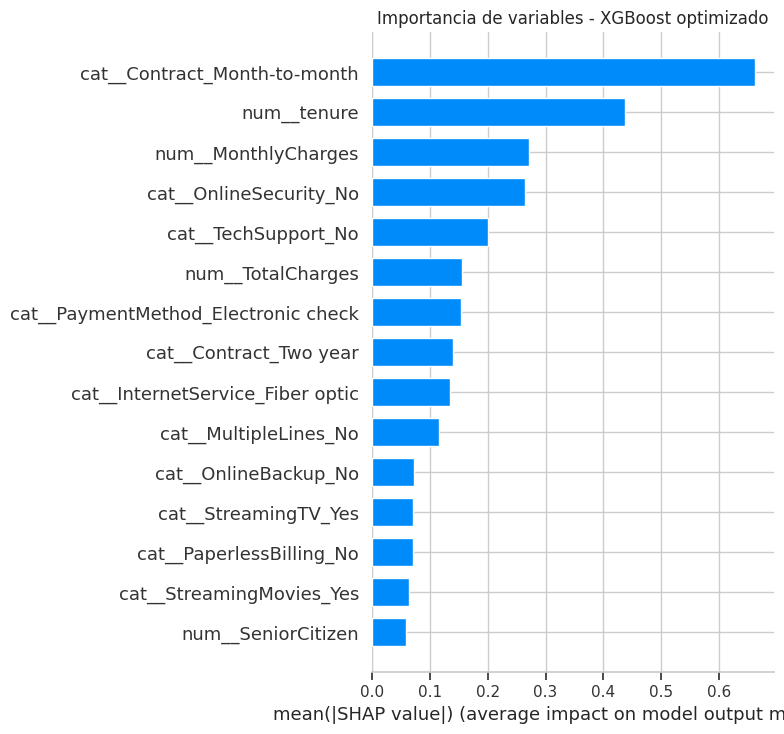

In [51]:

shap.summary_plot(
    shap_values,
    X_test_shap,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("Importancia de variables - XGBoost optimizado")
plt.tight_layout()
plt.show()


### Interpretabilidad del modelo mediante SHAP

Se utilizó SHAP (SHapley Additive exPlanations) para analizar la importancia de las variables en las predicciones del modelo XGBoost optimizado.

El análisis muestra que las variables con mayor contribución absoluta promedio son:

- **Tipo de contrato mensual (`Contract_Month-to-month`):** es la variable con mayor importancia global.
- **Antigüedad del cliente (`tenure`):** ocupa el segundo lugar, lo que destaca la relevancia de la permanencia del cliente.
- **Cargos mensuales (`MonthlyCharges`):** aparece en tercer lugar.
- **Servicios adicionales:** la ausencia de seguridad online y de soporte técnico también presenta una importancia relevante.

Estos resultados son consistentes con los patrones observados durante el análisis exploratorio, donde se identificó una asociación entre el abandono y los contratos mensuales, la menor antigüedad y los cargos mensuales.

Desde la perspectiva del negocio, estos hallazgos sugieren priorizar estrategias de retención para clientes con contratos mensuales, fortalecer el acompañamiento durante los primeros meses y evaluar propuestas de valor relacionadas con los servicios adicionales.

**Limitación:** el gráfico de barras SHAP representa la magnitud promedio de las contribuciones, pero no indica por sí solo si una variable aumenta o disminuye la probabilidad de abandono. Para interpretar la dirección de los efectos se requiere un gráfico SHAP de tipo *beeswarm* o análisis complementarios. La importancia tampoco implica causalidad.

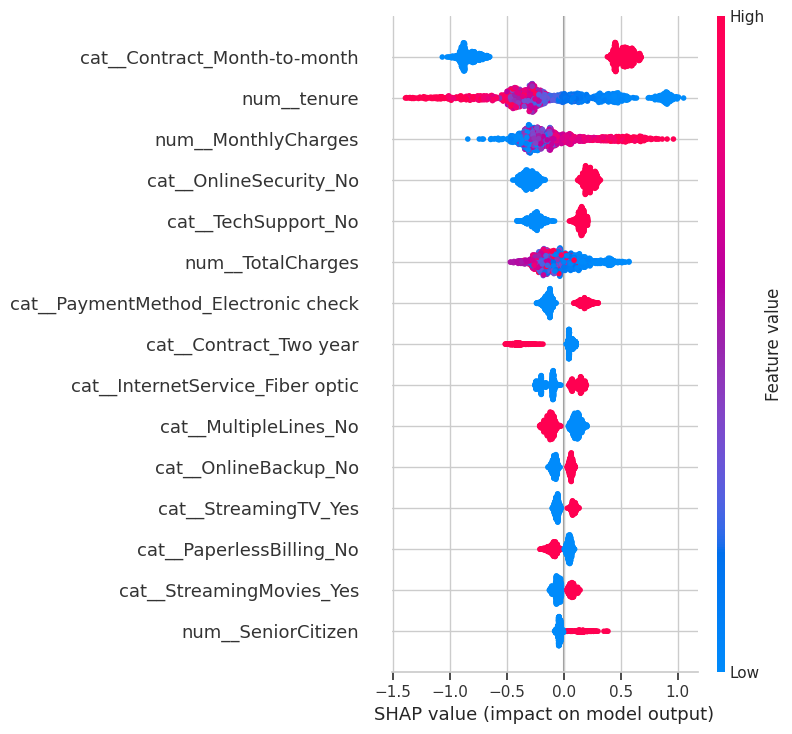

In [52]:

shap.summary_plot(
    shap_values,
    X_test_shap,
    max_display=15
)


### Interpretación de las predicciones mediante SHAP

El gráfico SHAP tipo *beeswarm* permite analizar la dirección y magnitud de la contribución de las variables a las predicciones del modelo XGBoost optimizado.

Los principales patrones observados son:

- Los contratos mensuales contribuyen a aumentar la probabilidad estimada de abandono.
- Una menor antigüedad del cliente se asocia con un mayor riesgo de churn.
- Los cargos mensuales elevados tienden a contribuir positivamente a la predicción de abandono.
- La ausencia de seguridad online y de soporte técnico aparece asociada con un mayor riesgo estimado.
- Los contratos de dos años tienden a contribuir hacia una menor probabilidad estimada de abandono.

Estos resultados permiten identificar perfiles de clientes que podrían requerir acciones de retención específicas. Por ejemplo, se podrían evaluar programas de acompañamiento durante los primeros meses y propuestas de contratación de mayor duración.

Las contribuciones SHAP explican el comportamiento del modelo y no demuestran relaciones causales. Las decisiones comerciales deberían validarse con información adicional y pruebas de negocio.

In [53]:

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

resultados_finales = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "Accuracy": accuracy_score(y_test, pipe_log.predict(X_test)),
        "ROC AUC": roc_auc_score(
            y_test,
            pipe_log.predict_proba(X_test)[:, 1]
        ),
        "Recall Churn": recall_score(
            y_test, pipe_log.predict(X_test), pos_label="Yes"
        )
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, pipe_rf.predict(X_test)),
        "ROC AUC": roc_auc_score(
            y_test,
            pipe_rf.predict_proba(X_test)[:, 1],
            labels=["No", "Yes"]
        ),
        "Recall Churn": recall_score(
            y_test, pipe_rf.predict(X_test), pos_label="Yes"
        )
    },
    {
        "Modelo": "XGBoost inicial",
        "Accuracy": accuracy_score(y_test_xgb, y_pred_xgb),
        "ROC AUC": roc_auc_score(y_test_xgb, y_proba_xgb),
        "Recall Churn": recall_score(
            y_test_xgb, y_pred_xgb, pos_label=1
        )
    },
    {
        "Modelo": "XGBoost optimizado",
        "Accuracy": accuracy_score(y_test_xgb, y_pred_best_xgb),
        "ROC AUC": roc_auc_score(
            y_test_xgb, y_proba_best_xgb
        ),
        "Recall Churn": recall_score(
            y_test_xgb, y_pred_best_xgb, pos_label=1
        )
    }
])

resultados_finales = resultados_finales.round(4)
display(resultados_finales)


,Modelo,Accuracy,ROC AUC,Recall Churn
0,Regresión Logística,0.8038,0.8359,0.5722
1,Random Forest,0.7875,0.8137,0.4840
2,XGBoost inicial,0.7861,0.8315,0.5214
3,XGBoost optimizado,0.7967,0.8388,0.5294


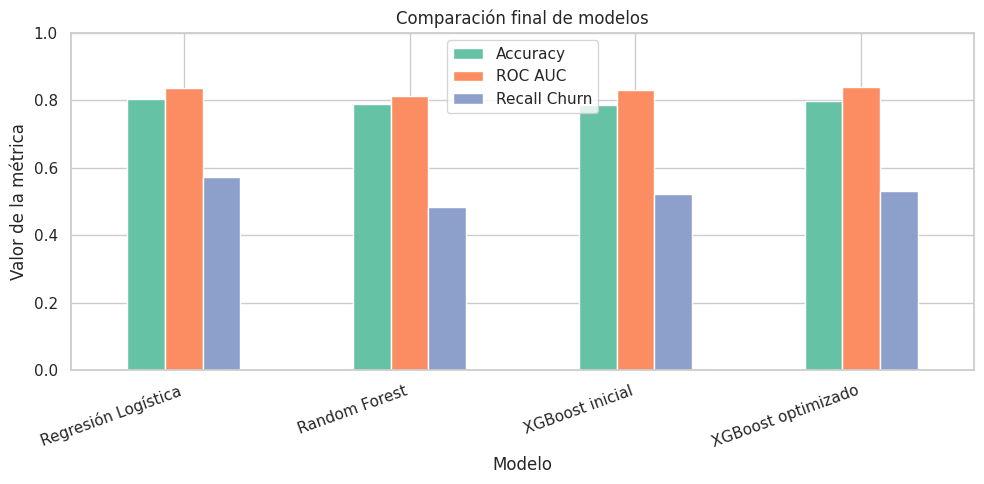

In [54]:

resultados_finales.set_index("Modelo")[
    ["Accuracy", "ROC AUC", "Recall Churn"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparación final de modelos")
plt.ylabel("Valor de la métrica")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## Conclusiones finales

### Comparación y selección del modelo

Se evaluaron cuatro alternativas: Regresión Logística, Random Forest, XGBoost inicial y XGBoost optimizado mediante GridSearchCV.

La Regresión Logística obtuvo un Accuracy de aproximadamente 80,38 %, un ROC AUC de 0,8359 y un Recall de 0,57 para la clase de abandono. Por su parte, XGBoost optimizado alcanzó un Accuracy de 79,67 %, un ROC AUC de 0,8388 y un Recall de 0,53.

La optimización de XGBoost mejoró sus métricas respecto del modelo inicial, aunque no logró superar a la Regresión Logística en Accuracy ni en Recall. Su ROC AUC de prueba fue ligeramente superior al de la Regresión Logística.

Considerando estos resultados, se propone mantener la Regresión Logística como modelo de referencia por su equilibrio entre las métricas evaluadas y utilizar XGBoost optimizado como alternativa competitiva. La elección definitiva deberá considerar también los costos de las acciones de retención, la capacidad operativa y el umbral de probabilidad seleccionado.

### Interpretabilidad y aplicación al negocio

El análisis SHAP de XGBoost identificó el tipo de contrato, la antigüedad, los cargos mensuales y la ausencia de determinados servicios de asistencia como variables relevantes para las predicciones.

Estos resultados permiten orientar futuras acciones de retención hacia clientes con contratos mensuales, poca antigüedad o necesidades de soporte que no estén cubiertas.

### Limitaciones y próximos pasos

Los modelos todavía dejan sin detectar una proporción importante de los clientes que abandonan el servicio. Por ello, sería conveniente evaluar umbrales de clasificación alternativos, analizar la relación entre Recall y Precision y estimar el costo económico de falsos positivos y falsos negativos.

Las asociaciones identificadas por los modelos no implican causalidad. Antes de implementar una estrategia comercial, las recomendaciones deberían validarse con pruebas controladas y seguimiento de resultados.

En conclusión, el proyecto integra análisis exploratorio, preparación de datos, entrenamiento, optimización, evaluación comparativa e interpretabilidad, y proporciona una base reproducible para desarrollar una estrategia de retención de clientes basada en datos.